### Prof. Alfio Ferrara

# Una rete a due livelli

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nel notebook precedente una rete con uno strato nascosto da 8 nodi ha imparato a classificare i climi delle città. Quegli 8 numeri per documento erano difficili da guardare. Ora costruiamo la stessa rete con un **livello intermedio di sole due dimensioni**: ogni documento sarà un punto del piano e potremo disegnarlo.

C'è di più. Ogni **parola** dell'ingresso ha nella rete una propria riga di parametri, e con due dimensioni anche quella riga è un punto del piano. Vedremo dove la rete mette le parole dopo aver imparato.

## Due livelli, due dimensioni

La rete ha due livelli di parametri: dalle parole al livello intermedio, dal livello intermedio alle cinque classi.

$$h = \tanh(xW_1 + b_1) \qquad s = hW_2 + b_2 \qquad p = \text{softmax}(s)$$

- $x$ è il vettore tf-idf del documento, con una componente per ogni parola del vocabolario.
- $W_1$ ha **una riga per ogni parola** e due colonne: ogni parola ha due numeri.
- $h$ ha due componenti: è la posizione del documento nel piano. La $\tanh$ la mantiene tra −1 e 1.
- $W_2$ porta quella posizione ai punteggi delle cinque classi.

Poiché $x$ è quasi tutto zero, il prodotto $xW_1$ è la **somma delle righe di $W_1$ delle sole parole presenti nel documento**, ciascuna moltiplicata per il peso tf-idf della parola. Rifacciamo il conto per un documento.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

classi_clima = ['tropicale', 'desertico', 'mediterraneo', 'temperato', 'polare']
colori_classi = plt.cm.tab10.colors[:5]
testi_tok = [re.findall(r'[^\W\d_]+', v['testo'].lower()) for v in dataset]
nomi_citta = np.array([v['citta'] for v in dataset])
y_tutti = np.array([classi_clima.index(v['clima']) for v in dataset])

def softmax(s):
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def prepara_dati(seed=0, per_classe_test=6):
    rng = np.random.default_rng(seed)
    test = np.zeros(len(dataset), dtype=bool)
    for c in range(len(classi_clima)):
        test[rng.permutation(np.flatnonzero(y_tutti == c))[:per_classe_test]] = True
    i_add, i_ver = np.flatnonzero(~test), np.flatnonzero(test)

    vocab = sorted({p for i in i_add for p in testi_tok[i]})
    posizione = {p: j for j, p in enumerate(vocab)}
    conteggi = np.zeros((len(dataset), len(vocab)))
    for i, parole_doc in enumerate(testi_tok):
        for p in parole_doc:
            if p in posizione:
                conteggi[i, posizione[p]] += 1

    idf_add = np.log(len(i_add) / (conteggi[i_add] > 0).sum(axis=0))
    tfidf_doc = conteggi / np.maximum(conteggi.sum(axis=1, keepdims=True), 1) * idf_add
    tfidf_doc /= np.maximum(np.linalg.norm(tfidf_doc, axis=1, keepdims=True), 1e-12)
    return {'Xa': tfidf_doc[i_add], 'ya': y_tutti[i_add], 'nomi_a': nomi_citta[i_add],
            'Xv': tfidf_doc[i_ver], 'yv': y_tutti[i_ver], 'vocabolario': np.array(vocab)}

dati = prepara_dati(seed=0)
V = len(dati['vocabolario'])

def inizializza(seed=0, n_nascosti=2):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(scale=0.1, size=(V, n_nascosti)), 'b1': np.zeros(n_nascosti),
            'W2': rng.normal(scale=0.1, size=(n_nascosti, 5)), 'b2': np.zeros(5)}

def avanti(par, X):
    h = np.tanh(X @ par['W1'] + par['b1'])
    return h, softmax(h @ par['W2'] + par['b2'])

par = inizializza()
print('parole nel vocabolario:', V)
print('W1:', par['W1'].shape, '| W2:', par['W2'].shape, '| parametri in tutto:', sum(v.size for v in par.values()))

parole nel vocabolario: 493
W1: (493, 2) | W2: (2, 5) | parametri in tutto: 1003


In [3]:
def scomponi(par, i, k=6):
    x = dati['Xa'][i]
    presenti = np.flatnonzero(x)
    contributi = x[presenti, None] * par['W1'][presenti]
    tabella = pd.DataFrame({'peso tf-idf': x[presenti], 'dim 1': contributi[:, 0], 'dim 2': contributi[:, 1]},
                           index=dati['vocabolario'][presenti])
    tabella = tabella.sort_values('peso tf-idf', ascending=False)
    somma = contributi.sum(axis=0)
    h = np.tanh(somma + par['b1'])
    print(f'documento: {dati["nomi_a"][i]} ({classi_clima[dati["ya"][i]]}), {len(presenti)} parole diverse')
    print(tabella.head(k).round(3).to_string())
    print(f'... altre {len(presenti) - k} parole')
    print(f'\nsomma delle righe pesate: {somma.round(3)}')
    print(f'tanh(somma + b1) = h:     {h.round(3)}')
    print(f'h calcolato dalla rete:   {avanti(par, dati["Xa"][i:i + 1])[0][0].round(3)}')

documento = 0
scomponi(par, documento)

documento: Singapore (tropicale), 29 parole diverse
           peso tf-idf  dim 1  dim 2
poco             0.306 -0.023  0.034
preavviso        0.306  0.042  0.011
singapore        0.306 -0.028  0.000
variano          0.306 -0.024  0.023
altra            0.306 -0.039  0.046
fa               0.256  0.007 -0.001
... altre 23 parole

somma delle righe pesate: [-0.079  0.156]
tanh(somma + b1) = h:     [-0.078  0.155]
h calcolato dalla rete:   [-0.078  0.155]


## Un momento di riflessione

- Quante parole ha il documento? Chi pesa di più nella somma, le parole con tf-idf alto o quelle con tf-idf basso?
- Se due documenti usano le stesse parole, dove finiscono nel piano? E se non hanno nessuna parola in comune?
- I valori nelle colonne «dim 1» e «dim 2» sono quasi zero. Perché? Da dove vengono i numeri di $W_1$ prima del training?
- Se cambiassimo la riga di una sola parola, quali documenti si muoverebbero?

## Prima del training: le parole nel piano

Ogni parola è una riga di $W_1$, cioè un punto. Disegniamo le parole che compaiono in almeno quattro documenti di addestramento, colorate secondo la classe in cui compaiono più spesso. A destra i **documenti**, nelle posizioni $h$ calcolate dalla rete, colorati con la classe vera. Lo sfondo mostra quale classe sceglierebbe la rete in ogni punto del piano.

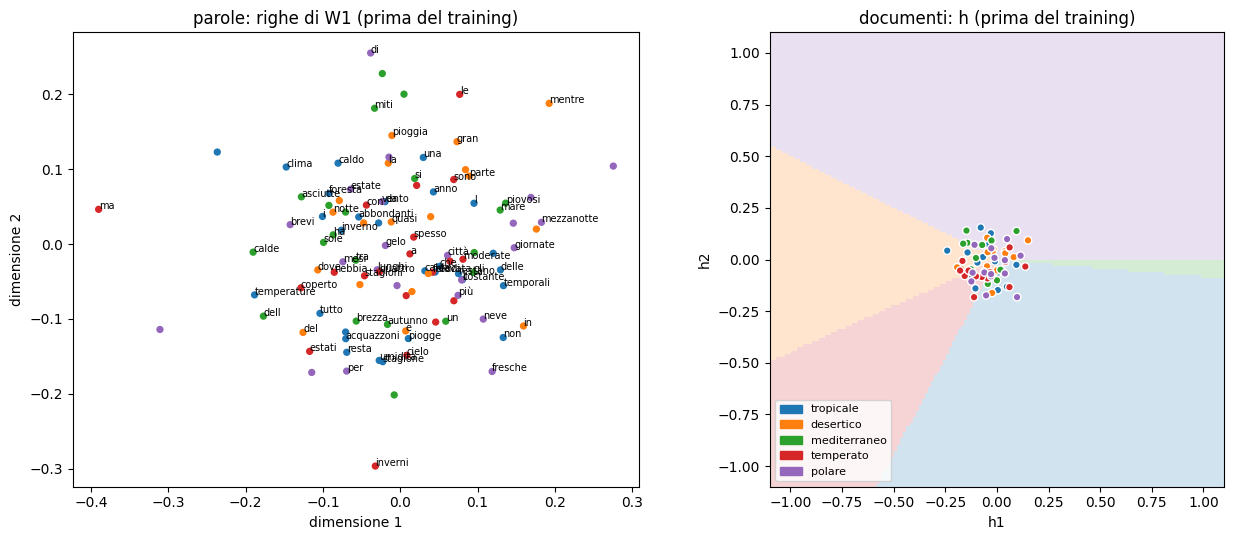

In [4]:
freq_classe = np.stack([(dati['Xa'][dati['ya'] == c] > 0).sum(axis=0) for c in range(5)], axis=1)
df_parole = freq_classe.sum(axis=1)
classe_prevalente = freq_classe.argmax(axis=1)
purezza = freq_classe.max(axis=1) / np.maximum(df_parole, 1)
visibili = df_parole >= 4
etichettate = visibili & ((df_parole >= 6) | ((purezza == 1) & (df_parole >= 5)))

def disegna_parole(ax, par, titolo, lim=None):
    W1 = par['W1']
    ax.scatter(W1[visibili, 0], W1[visibili, 1], c=[colori_classi[c] for c in classe_prevalente[visibili]], s=18)
    for j in np.flatnonzero(etichettate):
        ax.text(W1[j, 0], W1[j, 1], dati['vocabolario'][j], fontsize=7)
    if lim is not None:
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
    ax.set_title(titolo)
    ax.set_xlabel('dimensione 1')
    ax.set_ylabel('dimensione 2')

def disegna_documenti(ax, par, titolo):
    g = np.linspace(-1.1, 1.1, 150)
    griglia = np.array(np.meshgrid(g, g)).reshape(2, -1).T
    regioni = softmax(griglia @ par['W2'] + par['b2']).argmax(axis=1).reshape(150, 150)
    ax.imshow(regioni, extent=[-1.1, 1.1, -1.1, 1.1], origin='lower', alpha=0.2, cmap=ListedColormap(colori_classi), vmin=0, vmax=4)
    h = avanti(par, dati['Xa'])[0]
    ax.scatter(h[:, 0], h[:, 1], c=[colori_classi[c] for c in dati['ya']], s=30, edgecolor='white')
    ax.set_title(titolo)
    ax.set_xlabel('h1')
    ax.set_ylabel('h2')

def legenda(ax):
    ax.legend(handles=[Patch(color=c, label=n) for c, n in zip(colori_classi, classi_clima)], fontsize=8, loc='lower left')

fig, assi = plt.subplots(1, 2, figsize=(13, 5.5))
disegna_parole(assi[0], par, 'parole: righe di W1 (prima del training)')
disegna_documenti(assi[1], par, 'documenti: h (prima del training)')
legenda(assi[1])
plt.tight_layout()
plt.show()

## Un momento di riflessione

- Come sono disposte le parole? C'è un legame tra la posizione e il colore?
- Dove stanno i documenti? Riescono a stare in zone diverse del piano?
- La rete non ha ancora visto nessun esempio. Che cosa ci dice sul fatto che la posizione nel piano non ha, per ora, alcun significato?
- Il colore di una parola viene dai documenti dell'addestramento, non dalla rete. Perché è utile per controllare che cosa impara?

## Il training

Alleniamo la rete come nel notebook precedente: gradiente dell'errore sui documenti di addestramento, 150 passi con $\eta = 2$. Con la tanh la derivata è $1 - h^2$. Salviamo le posizioni dei parametri in alcuni momenti per vedere le parole muoversi.

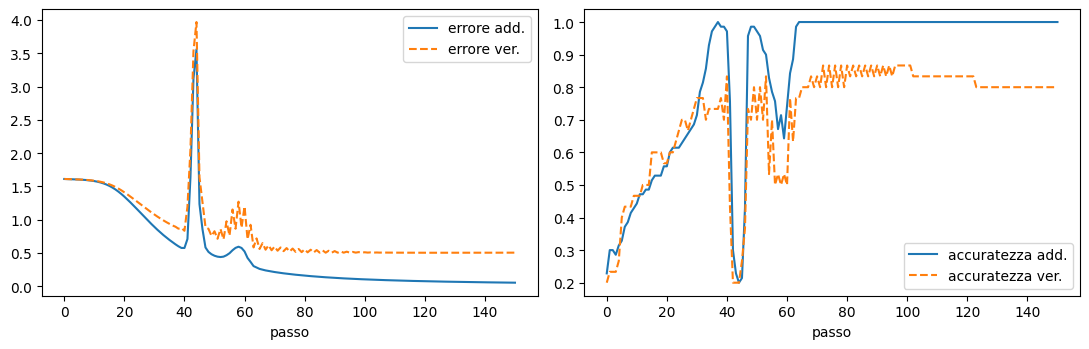

     errore add.  errore ver.  accuratezza add.  accuratezza ver.
0          1.610        1.610             0.229             0.200
10         1.578        1.584             0.443             0.467
30         0.889        1.075             0.714             0.767
150        0.051        0.503             1.000             0.800


In [5]:
def addestra(par, dati, eta=2.0, passi=150, istanti=(0, 10, 30, 150)):
    par = {k: v.copy() for k, v in par.items()}
    Y = np.eye(5)[dati['ya']]
    storia, istantanee = [], {}
    for t in range(passi + 1):
        h, p = avanti(par, dati['Xa'])
        _, pv = avanti(par, dati['Xv'])
        storia.append({
            'errore add.': -np.log(p[np.arange(len(dati['ya'])), dati['ya']]).mean(),
            'errore ver.': -np.log(pv[np.arange(len(dati['yv'])), dati['yv']]).mean(),
            'accuratezza add.': (p.argmax(axis=1) == dati['ya']).mean(),
            'accuratezza ver.': (pv.argmax(axis=1) == dati['yv']).mean(),
        })
        if t in istanti:
            istantanee[t] = {k: v.copy() for k, v in par.items()}
        ds = (p - Y) / len(Y)
        dz = (ds @ par['W2'].T) * (1 - h ** 2)
        par['W1'] -= eta * dati['Xa'].T @ dz
        par['b1'] -= eta * dz.sum(axis=0)
        par['W2'] -= eta * h.T @ ds
        par['b2'] -= eta * ds.sum(axis=0)
    return par, pd.DataFrame(storia), istantanee

par_finale, storia, istantanee = addestra(par, dati)

fig, assi = plt.subplots(1, 2, figsize=(11, 3.6))
storia[['errore add.', 'errore ver.']].plot(ax=assi[0], style=['-', '--'])
storia[['accuratezza add.', 'accuratezza ver.']].plot(ax=assi[1], style=['-', '--'])
for ax in assi:
    ax.set_xlabel('passo')
plt.tight_layout()
plt.show()

print(storia.iloc[[0, 10, 30, 150]].round(3).to_string())

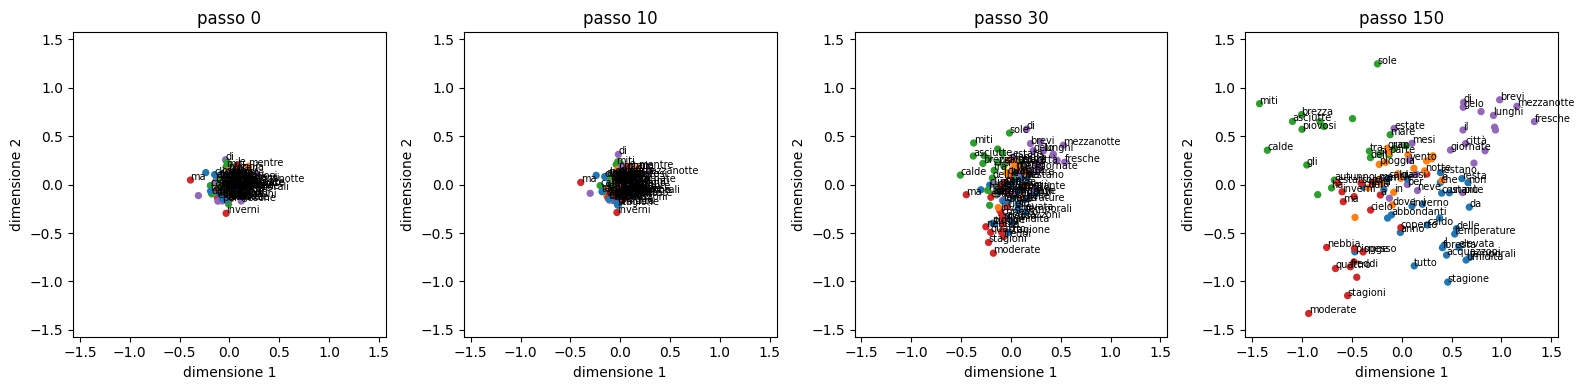

In [6]:
limite = 1.1 * max(np.abs(s['W1'][visibili]).max() for s in istantanee.values())
fig, assi = plt.subplots(1, len(istantanee), figsize=(4 * len(istantanee), 4))
for ax, (passo, s) in zip(assi, istantanee.items()):
    disegna_parole(ax, s, f'passo {passo}', lim=limite)
plt.tight_layout()
plt.show()

## Un momento di riflessione

- Quanto è accurata la rete sui documenti di addestramento? E su quelli di verifica? Con due sole dimensioni vi aspettavate di più o di meno rispetto agli 8 nodi del notebook precedente?
- Guardate le parole nei quattro istanti. Quali si muovono per prime? Si muovono tutte nello stesso modo?
- Chi ha detto alla rete dove mettere le parole? Dove compare l'informazione sulle classi, nell'addestramento?
- Il verso in cui si sposta una parola dipende dalle classi dei documenti in cui compare. Come si ricollega al gradiente di un singolo parametro del notebook precedente?

## Dopo il training: parole e documenti

Rifacciamo i due disegni con i parametri appresi.

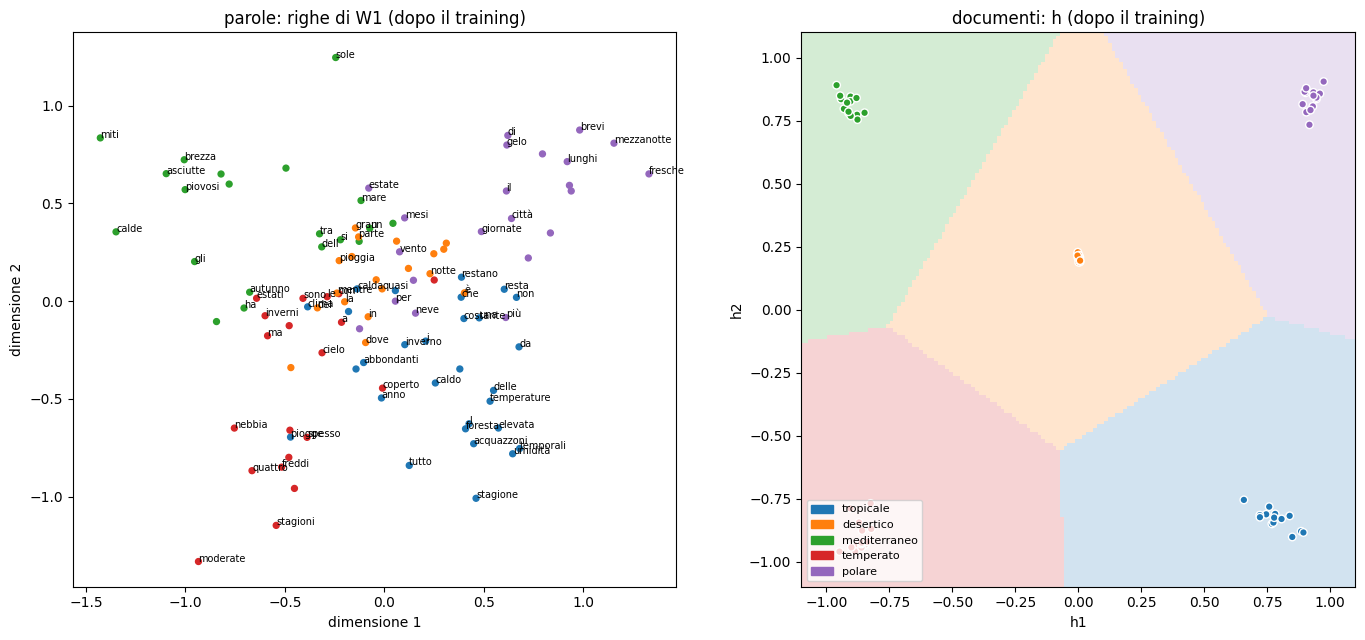

In [7]:
fig, assi = plt.subplots(1, 2, figsize=(14, 6.5))
disegna_parole(assi[0], par_finale, 'parole: righe di W1 (dopo il training)')
disegna_documenti(assi[1], par_finale, 'documenti: h (dopo il training)')
legenda(assi[1])
plt.tight_layout()
plt.show()

In [8]:
scomponi(par_finale, documento)

documento: Singapore (tropicale), 29 parole diverse
           peso tf-idf  dim 1  dim 2
poco             0.306  0.043 -0.041
preavviso        0.306  0.108 -0.065
singapore        0.306  0.038 -0.076
variano          0.306  0.042 -0.053
altra            0.306  0.028 -0.029
fa               0.256  0.044 -0.058
... altre 23 parole

somma delle righe pesate: [ 0.932 -1.192]
tanh(somma + b1) = h:     [ 0.769 -0.85 ]
h calcolato dalla rete:   [ 0.769 -0.85 ]


## Un momento di riflessione

- Come si dispongono ora i documenti? E le parole? Le parole dello stesso colore stanno vicine?
- Perché i documenti di una classe finiscono in un angolo, mentre le parole sono sparse in tutto il piano?
- Una parola come *miti* o *stagioni* ha una riga lunga, una parola poco frequente ha una riga quasi nulla. Che cosa influisce sulla distanza dall'origine?
- Nel conto passo passo dell'ultimo documento, quali parole contribuiscono di più a spostarlo? Sono quelle che ci aspettiamo?
- Il documento è la somma pesata dei vettori delle sue parole. Che cosa significa, per il testo, che due parole abbiano vettori vicini?

## Chi sta vicino a chi

Se la posizione di una parola ha un significato, parole vicine dovrebbero comportarsi in modo simile. Per ogni classe prendiamo la parola più frequente tra quelle che compaiono quasi solo in quella classe e guardiamo le sue vicine nel piano, tra le parole che compaiono in almeno quattro documenti. Poi misuriamo quanto spesso le cinque vicine più vicine hanno la stessa classe prevalente: prima e dopo il training.

In [9]:
candidate = np.flatnonzero(visibili)

def vicine(par, j, k=5):
    distanze = np.linalg.norm(par['W1'][candidate] - par['W1'][j], axis=1)
    ordine = candidate[np.argsort(distanze)]
    return [p for p in ordine if p != j][:k]

def quota_stessa_classe(par, k=5):
    return np.mean([np.mean([classe_prevalente[v] == classe_prevalente[j] for v in vicine(par, j, k)]) for j in candidate])

righe = []
for c in range(5):
    j = candidate[np.argmax(np.where((classe_prevalente[candidate] == c) & (purezza[candidate] >= 0.9), df_parole[candidate], -1))]
    righe.append((classi_clima[c], dati['vocabolario'][j], ', '.join(dati['vocabolario'][vicine(par_finale, j)])))
print(pd.DataFrame(righe, columns=['classe', 'parola', 'cinque parole più vicine']).to_string(index=False))

print(f'\nquota di vicine con la stessa classe prevalente:')
print(f'  prima del training:  {quota_stessa_classe(par):.2f}')
print(f'  dopo il training:    {quota_stessa_classe(par_finale):.2f}')
print(f'  a caso, in media:    {sum((np.bincount(classe_prevalente[candidate]) / len(candidate)) ** 2):.2f}')

      classe     parola                      cinque parole più vicine
   tropicale acquazzoni       foresta, l, elevata, umidità, temporali
   desertico    pioggia               giorno, si, dell, fredde, parte
mediterraneo     brezza   asciutte, piovosi, soleggiate, secche, miti
   temperato   moderate     stagioni, quattro, frequenti, freddi, ben
      polare     lunghi ghiacciato, polare, gelidi, brevi, mezzanotte

quota di vicine con la stessa classe prevalente:
  prima del training:  0.20
  dopo il training:    0.59
  a caso, in media:    0.21


## Un momento di riflessione

- Le parole vicine hanno un legame che riconoscete? Sono sinonimi, parole dello stesso campo semantico o semplicemente parole che compaiono negli stessi documenti?
- Prima del training la quota di vicine nella stessa classe è vicina al caso, dopo è molto più alta. Che cosa è cambiato, e che cosa non è cambiato, nei dati?
- Due parole con lo stesso significato, mai usate nello stesso documento ma in documenti della stessa classe: ci aspettiamo che la rete le metta vicine? E due sinonimi che compaiono in classi diverse?
- Le posizioni dipendono dal compito: abbiamo chiesto di prevedere il clima. Con un compito diverso (l'autore, il genere, la parola successiva) le stesse parole finirebbero nello stesso punto?
- Che cosa succede a una parola che non era nel vocabolario dell'addestramento?

## Cosa abbiamo visto

1. Una rete a **due livelli** ha due matrici di parametri. Con un livello intermedio di **due dimensioni** ogni documento diventa un punto del piano.
2. Ogni parola ha la sua **riga di parametri** in $W_1$: con due dimensioni è un punto del piano. Il documento è la somma pesata delle righe delle sue parole.
3. Prima del training le posizioni sono **casuali** e non significano nulla. Imparare a classificare **sposta le parole**: quelle che compaiono nei documenti della stessa classe vanno nella stessa zona.
4. Nessuno ha detto alla rete dove mettere le parole: la loro posizione è un sottoprodotto del compito. Questa è l'intuizione alla base degli **embedding**: un vettore appreso per ogni parola, la cui posizione riflette il modo in cui la parola è usata.

Restano aperte alcune domande su come procedere:

- **Il compito decide il significato?** Qui le posizioni riflettono solo i cinque climi. Quale compito farebbe emergere somiglianze più generali tra le parole?
- **Più di due dimensioni.** Con 8, 50 o 300 dimensioni la rete ha più spazio, ma non possiamo più disegnarla. Come si guardano i vettori? (proiezioni, distanze, vicini)
- **Parole mai viste e parole rare.** Una parola senza riga non ha vettore, una parola rara ne ha uno poco affidabile. Come si imparano i vettori da molti più testi?
- **Dalle parole al contesto.** In questa rete una parola ha sempre lo stesso vettore e l'ordine delle parole non conta. Che cosa serve per distinguere «banco di scuola» da «banco di pesci»?